# Кластеризация котиков 🐈

## Семинар 6

Попробуем сгруппировать похожие изображения без готовых меток. Представим
изображение вектором пикселей, исследуем расстояния, сократим число признаков
с помощью PCA и подберём число кластеров для KMeans.


### 1. Данные и визуализация

Положите выданный преподавателем `cats.zip` в одну папку с ноутбуком.
Ячейка ниже распакует из него `cats.csv` в эту же папку и прочитает таблицу.

В архиве один файл `cats.csv`: 5 000 случайных фотографий кошачьих мордочек
64 × 64 и готовые эмбеддинги DINOv2. Выборка сделана без повторений с `seed=42`.
Каждая строка содержит:
- `filename` — имя изображения;
- `embedding_0`, …, `embedding_383` — 384 числовых признака;
- `image_base64` — JPEG-фотографию, закодированную текстом, в последней колонке.

In [43]:
from base64 import b64decode
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

seed = 42
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})

In [44]:
archive_path = Path("cats.zip")
if not archive_path.is_file():
    raise FileNotFoundError("Положите cats.zip в одну папку с ноутбуком и запустите его из этой папки.")

with ZipFile(archive_path) as archive:
    archive.extract("cats.csv", path=archive_path.parent)

csv_path = archive_path.with_suffix(".csv")
embedding_columns = [f"embedding_{i}" for i in range(384)]
cats = pd.read_csv(csv_path, dtype={c: "float32" for c in embedding_columns})
print(f"Архив распакован: {csv_path}. Изображений: {len(cats):,}")

# Небольшой просмотр числовых данных, без длинных строк изображений.
cats[["filename", *embedding_columns[:4]]].head()

Архив распакован: cats.csv. Изображений: 5,000


,filename,embedding_0,embedding_1,embedding_2,embedding_3
0,cats/all/10002.jpg,-3.364418,-0.128904,-3.569957,-0.048969
1,cats/all/1001.jpg,-2.728636,-0.526696,-8.244587,-0.834988
2,cats/all/10011.jpg,-1.214301,-1.462029,-5.526106,1.452526
3,cats/all/10012.jpg,-0.308691,-1.485432,-5.085827,-1.486969
4,cats/all/10017.jpg,0.862096,-2.042634,-2.473871,-0.850671


Изображение, имя файла и эмбеддинг берём из одной строки: их порядок совпадает.
CSV уже распакован предыдущей ячейкой и прочитан в таблицу `cats`

In [45]:
files = cats["filename"].to_numpy()
embeddings = cats[embedding_columns].to_numpy()
images = np.stack([
    np.array(Image.open(BytesIO(b64decode(value))).convert("RGB"))
    for value in cats["image_base64"]
])

print(f"Изображений: {len(images)}, размер: {images.shape[1:]}")
print(f"Эмбеддинги: {embeddings.shape}")

Изображений: 5000, размер: (64, 64, 3)
Эмбеддинги: (5000, 384)


Готовая функция `show_images` принимает массив изображений, заголовок и число
столбцов. Её можно использовать и для случайных котиков, и для отдельных кластеров.


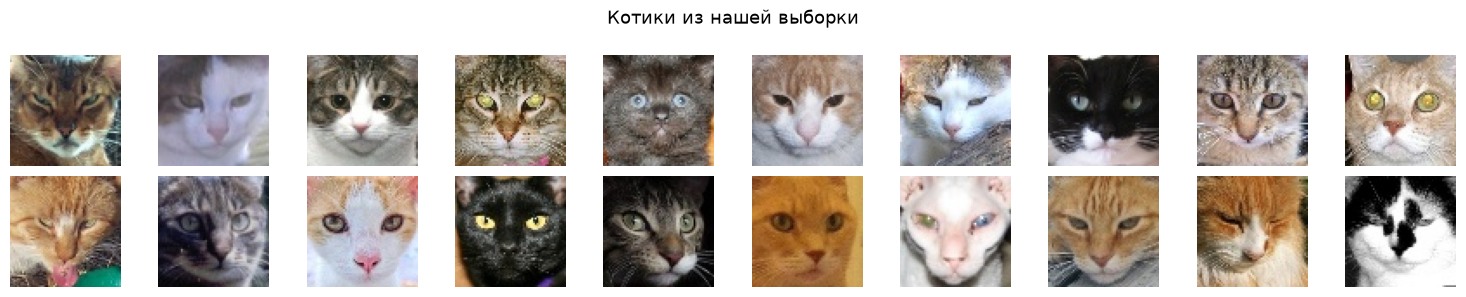

In [46]:
def show_images(images, title="", cols=10):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(
        rows, cols, figsize=(1.5 * cols, 1.5 * rows), squeeze=False
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        ax.imshow(image)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_images(images[:20], "Котики из нашей выборки")


### 2. Расстояния в пространстве котиков

Развернём каждую картинку в вектор из 64 × 64 × 3 = 12 288 признаков и переведём
значения пикселей из диапазона 0–255 в 0–1

Мы исследуем геометрию имеющихся данных, поэтому обучающая и тестовая выборки
здесь не нужны. Породы или другие готовые метки в алгоритмы не передаём.

`X` — матрица признаков, `y` — номера кластеров после KMeans. Пока кластеры не получены, `y = None`: готовых меток в датасете нет.


In [47]:
X = images.reshape(len(images), -1).astype("float32") / 255
y = None
X.shape

(5000, 12288)

#### Эмбеддинги вместо пикселей

Вместо пикселей можно использовать эмбеддинг — векторное представление,
полученное с помощью нейросети. Мы уже прочитали готовые эмбеддинги из CSV
в массив `embeddings`. У каждого изображения 384 признака; `normalize`
приводит вектор к единичной длине.

In [48]:
X, y = normalize(embeddings), None
X.shape

(5000, 384)

Выберем 10 000 случайных пар разных изображений и посчитаем евклидовы
расстояния. Нормируем их на среднее. Те же пары используем после PCA.

In [49]:
rng = np.random.default_rng(seed)
left = rng.integers(len(X), size=10_000)
right = (left + rng.integers(1, len(X), size=10_000)) % len(X)


def pair_distances(data):
    distances = np.empty(len(left))
    for start in range(0, len(left), 500):
        batch = slice(start, start + 500)
        diff = data[left[batch]] - data[right[batch]]
        distances[batch] = np.linalg.norm(diff, axis=1)
    return distances / distances.mean()


distances = {"До PCA": pair_distances(X)}

### 3. Как PCA меняет расстояния

Обучим PCA на всех объектах. Сравним 30, 100 и 500 компонент.
Если признаков меньше 500, в последнем варианте используем все доступные
компоненты: для DINOv2 их 384. PCA сам центрирует признаки;
`whiten=True` не используем.

Сравним разброс расстояний в таблице. Стандартное отклонение нормированных
расстояний равно коэффициенту вариации исходных расстояний: чем оно меньше,
тем сильнее концентрация относительно среднего.

In [50]:
dims = [30, 100, min(500, *X.shape)]
pca = PCA(n_components=dims[-1], svd_solver="randomized", random_state=seed)
components = pca.fit_transform(X)

for n in dims:
    distances[f"PCA: {n}"] = pair_distances(components[:, :n])

In [51]:
spread = pd.DataFrame({
    name: {"Стандартное отклонение": values.std(),
           "Квантиль 5%": np.quantile(values, 0.05),
           "Квантиль 95%": np.quantile(values, 0.95)}
    for name, values in distances.items()
}).T
spread["Сохранённая дисперсия"] = [
    1, *[pca.explained_variance_ratio_[:n].sum() for n in dims]
]
spread.round(3)


,Стандартное отклонение,Квантиль 5%,Квантиль 95%,Сохранённая дисперсия
До PCA,0.146,0.729,1.211,1.000
PCA: 30,0.189,0.651,1.272,0.747
PCA: 100,0.156,0.709,1.225,0.916
PCA: 384,0.146,0.729,1.211,1.000


### 4. KMeans и выбор числа кластеров

Используем 100 главных компонент и переберём от 2 до 8 кластеров.
KMeans обучается на всей выборке. Для ускорения силуэт оцениваем на одной и той же
случайной подвыборке из 1 500 изображений. Чем больше силуэт, тем лучше разделены
кластеры по выбранной метрике; значения около нуля означают сильное перекрытие.

Для каждого числа кластеров делаем 10 запусков с разными начальными центрами.
Выбираем модель с максимальным силуэтом среди проверенных вариантов.


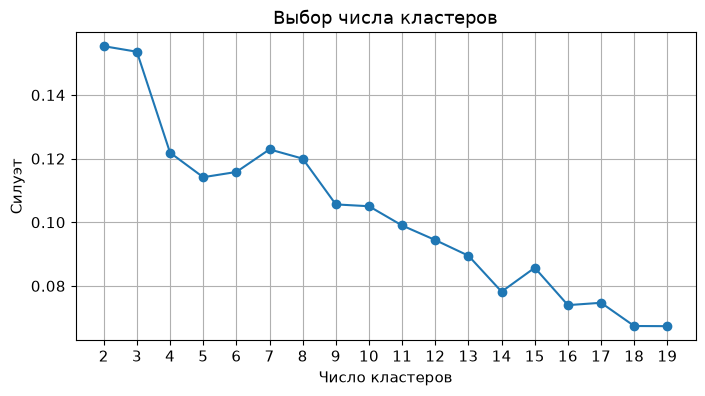

,Силуэт
Число кластеров,
2,0.155
3,0.154
4,0.122
5,0.114
6,0.116
7,0.123
8,0.120
9,0.106
10,0.105


In [52]:
features = components[:, :100]
models, scores = {}, {}

for k in range(2, 20):
    model = KMeans(n_clusters=k, n_init=10, random_state=seed, init="k-means++").fit(features)
    models[k] = model
    scores[k] = silhouette_score(
        features, model.labels_, sample_size=1500, random_state=seed
    )

scores = pd.Series(scores, name="Силуэт").rename_axis("Число кластеров")
scores.plot(marker="o", xticks=scores.index, ylabel="Силуэт", grid=True)
plt.title("Выбор числа кластеров")
plt.show()
scores.round(3).to_frame()


#### Кластеры на плоскости при разных k

На всех графиках одни и те же точки в первых двух компонентах PCA и одинаковый
масштаб. Меняется только разбиение на кластеры. Чёрные крестики — проекции
центров кластеров; в заголовках указаны `k` и силуэт.

KMeans обучен на 100 компонентах. Двумерная проекция теряет часть информации,
поэтому группы на рисунке могут перекрываться. Номера и цвета кластеров
между разными `k` не согласованы.

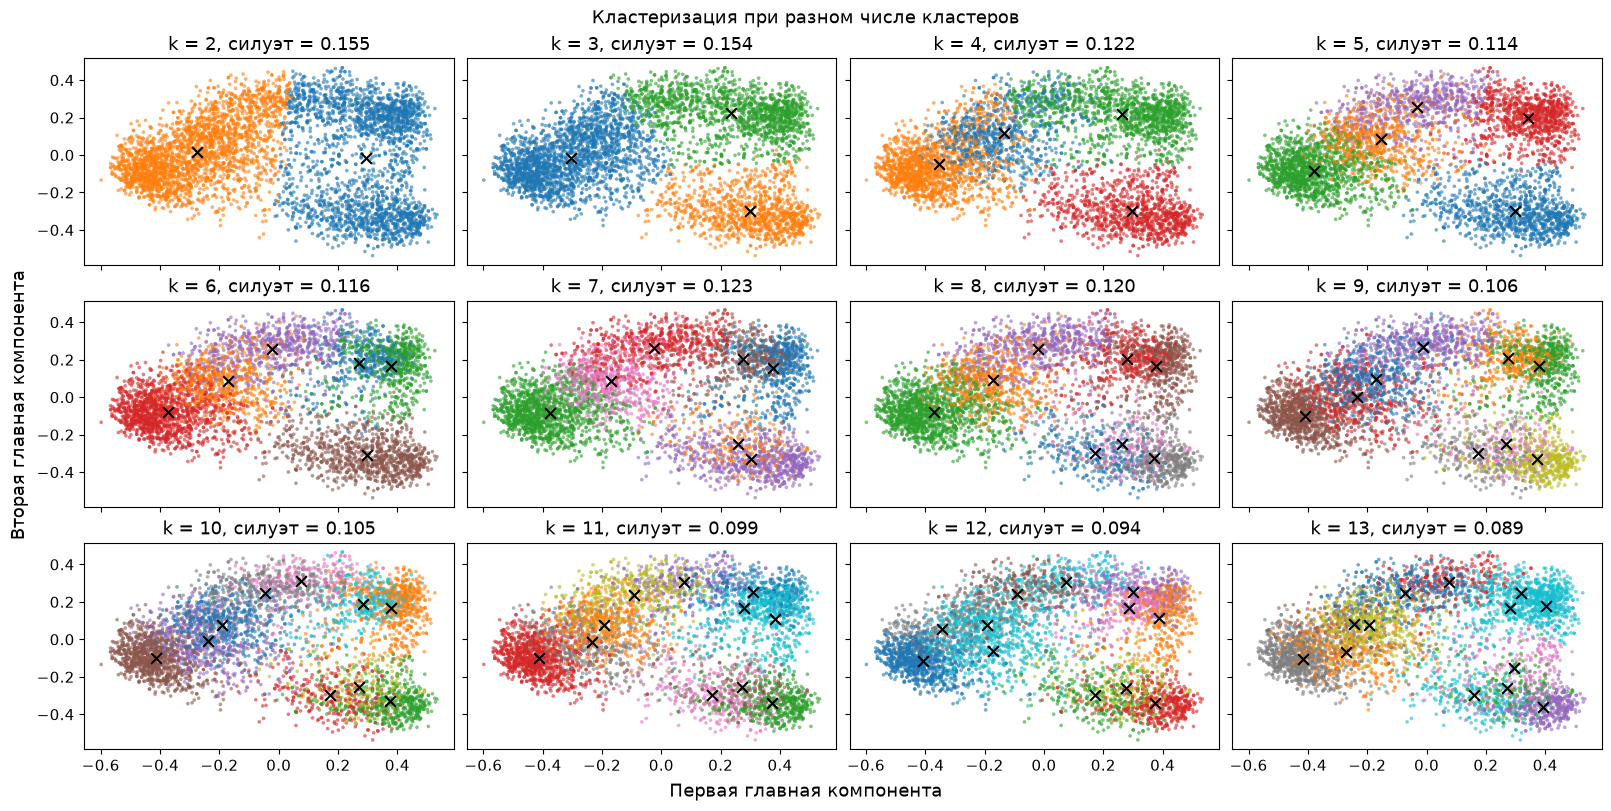

In [53]:
points = features[:, :2]
fig, axes = plt.subplots(
    3, 4, figsize=(16, 8), sharex=True, sharey=True, layout="constrained"
)
for ax, (k, model) in zip(axes.flat, models.items()):
    ax.scatter(
        points[:, 0], points[:, 1], c=model.labels_, cmap="tab10",
        vmin=0, vmax=9, s=7, alpha=0.6, linewidths=0,
    )
    centers = model.cluster_centers_[:, :2]
    ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="x", s=60)
    ax.set_title(f"k = {k}, силуэт = {scores[k]:.3f}")
for ax in axes.flat[len(models):]:
    ax.set_visible(False)
fig.supxlabel("Первая главная компонента")
fig.supylabel("Вторая главная компонента")
fig.suptitle("Кластеризация при разном числе кластеров")
plt.show()

In [54]:
best_k = int(scores.idxmax())
best_k = 3
model = models[best_k]
y = model.labels_

print(f"Число кластеров: {best_k}, силуэт: {scores[best_k]:.3f}")
sizes = pd.Series(y + 1).value_counts().sort_index()
sizes.rename_axis("Кластер").to_frame("Изображений")


Число кластеров: 3, силуэт: 0.154


,Изображений
Кластер,
1,2300
2,1104
3,1596


### 5. Какие котики попали в каждый кластер

Покажем по 20 случайных изображений из каждого кластера, по две строки.
Ищем общие черты: яркость, окрас, положение мордочки и фон. Номер кластера —
условное обозначение, а не порода и не оценка качества котика.


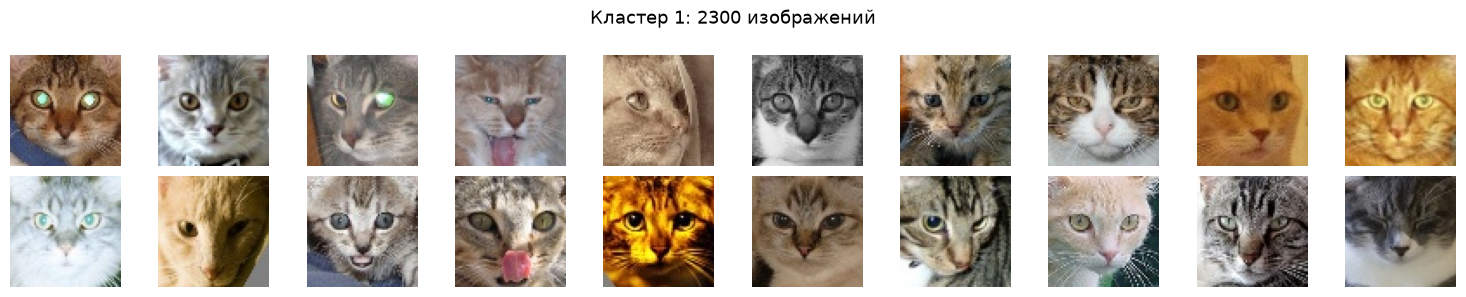

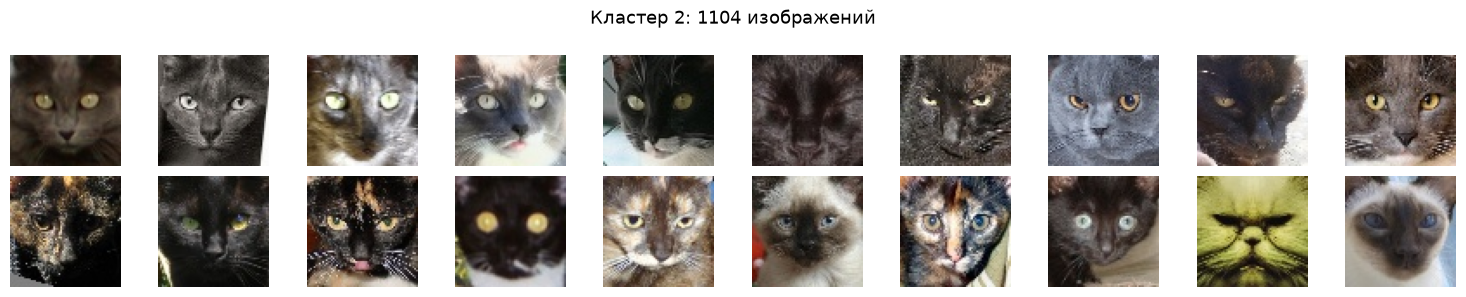

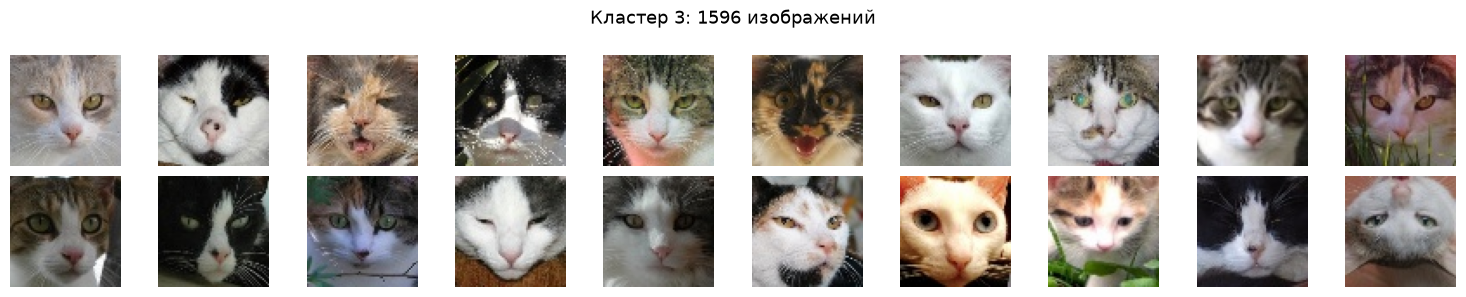

In [55]:
rng = np.random.default_rng(seed)

for cluster in range(best_k):
    members = np.flatnonzero(y == cluster)
    sample = rng.choice(members, size=min(20, len(members)), replace=False)
    show_images(images[sample], f"Кластер {cluster + 1}: {len(members)} изображений")


Усредним исходные изображения внутри кластеров и сравним полученные картинки.

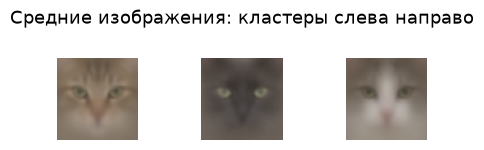

In [56]:
means = np.stack([
    images[y == cluster].mean(axis=0) / 255 for cluster in range(best_k)
])
show_images(means, "Средние изображения: кластеры слева направо", cols=best_k)


### Для обсуждения

- Как меняются группы при увеличении `k`?
- Как изменились расстояния и кластеры после перехода от пикселей к DINOv2?
- Какие общие черты видны у котиков внутри каждого кластера?
- Почему двумерная проекция не показывает все различия между объектами?